# How Good Are LLMs at 20 Questions? — pilot harness
**Answerer** = model holding the secret word. **Guesser** = model asking yes/no questions.
Every game is appended to a JSONL file on Google Drive so nothing is lost if Colab disconnects.

In [ ]:
!pip -q install openai pandas matplotlib

We are using the entity deduction arena dataset from hugging face. It uses a list of things, and celebrities.

In [ ]:
#Previewing EDA dataset files for download
from huggingface_hub import list_repo_files
REPO = "yizheapple/entity-deduction-arena"
files = list_repo_files(REPO, repo_type="dataset")
print(files)

['.gitattributes', 'README.md', 'celebs/dev.txt', 'celebs/test.txt', 'celebs/train.txt', 'dataset_dict.py', 'dataset_info.json', 'entity-deduction-arena.py', 'things/dev.txt', 'things/test.txt', 'things/train.txt']


In [ ]:
import json, csv, os
from huggingface_hub import hf_hub_download

TEST_FILES = {
    "thing":  "things/test.txt",
    "person": "celebs/test.txt",
}

def load_words(path):
    ext = os.path.splitext(path)[1].lower()
    with open(path, encoding="utf-8") as f:
        if ext == ".json":
            data = json.load(f)
        elif ext == ".jsonl":
            data = [json.loads(l) for l in f if l.strip()]
        elif ext in (".csv", ".tsv"):
            data = list(csv.reader(f, delimiter="\t" if ext == ".tsv" else ","))
        else:  # .txt: one word per line
            data = [l.strip() for l in f if l.strip()]
    # flatten: handle plain strings, rows, or dicts
    out = []
    for d in data:
        if isinstance(d, str): out.append(d)
        elif isinstance(d, list): out.append(d[0])
        elif isinstance(d, dict): out.append(next(iter(d.values())))
    return out

EDA = {}
for cat, fname in TEST_FILES.items():
    path = hf_hub_download(REPO, fname, repo_type="dataset")
    EDA[cat] = load_words(path)
    print(cat, len(EDA[cat]), EDA[cat][:10])

thing 100 ['Oar', 'Chive', 'Sloth', 'Citadel', 'Marble', 'CelloMarshmallow', 'Mouse', 'Dungeon', 'Seagull', 'Raincoat']
person 100 ['Saoirse Ronan', 'J.K. Rowling', 'Michael Jackson', 'George Lucas', 'Michael Jordan', 'Yoko Shimomura', 'Marilyn Monroe', 'Charles Dickens', 'Reese Witherspoon', 'Oscar Wilde']


In [ ]:
import re

def fix_merged(words):
    out = []
    for w in words:
        # split "CelloMarshmallow" -> "Cello", "Marshmallow" (lowercase letter directly followed by uppercase)
        parts = re.split(r"(?<=[a-z])(?=[A-Z])", w)
        if len(parts) > 1:
            print("split:", w, "->", parts)
        out.extend(parts)
    return out

EDA["thing"] = fix_merged(EDA["thing"])
print("things:", len(EDA["thing"]))
WORDS = EDA

split: CelloMarshmallow -> ['Cello', 'Marshmallow']
things: 101


In [ ]:
# ---- Keys & storage ----
# Colab: click the key icon in the left sidebar -> add secret OPENROUTER_API_KEY -> toggle "Notebook access" on.
import os, json, re, time, random, itertools, uuid
from datetime import datetime, timezone
from google.colab import userdata, drive
from openai import OpenAI

drive.mount("/content/drive")
OUT_DIR = "/content/drive/MyDrive/cse519_20q"
os.makedirs(OUT_DIR, exist_ok=True)
LOG_PATH = f"{OUT_DIR}/games.jsonl"

client = OpenAI(
    base_url="https://openrouter.ai/api/v1",
    api_key=userdata.get("OPENROUTER_API_KEY").strip(),
)



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# This is checking that we can see Maaz's saved games before running anything
print(os.listdir(OUT_DIR))

['games.jsonl']


In [ ]:
# ---- Find the exact model IDs (they change often; never trust a hard-coded slug) ----
def find_models(*keywords):
    ids = [m.id for m in client.models.list().data]
    return sorted(i for i in ids if any(k.lower() in i.lower() for k in keywords))

for kw in ["anthropic/claude", "openai/gpt", "google/gemini", "deepseek", "meta-llama", "qwen"]:
    print(kw, "->", find_models(kw))

anthropic/claude -> ['anthropic/claude-fable-5', 'anthropic/claude-fable-5.1', 'anthropic/claude-fable-5.1:batch', 'anthropic/claude-fable-5.2', 'anthropic/claude-fable-5.2:batch', 'anthropic/claude-haiku-4.5', 'anthropic/claude-haiku-5.5', 'anthropic/claude-haiku-5.5:batch', 'anthropic/claude-opus-4.1', 'anthropic/claude-opus-4.5', 'anthropic/claude-opus-4.6', 'anthropic/claude-opus-4.7', 'anthropic/claude-opus-4.8', 'anthropic/claude-opus-5', 'anthropic/claude-opus-5.5', 'anthropic/claude-opus-5.5:batch', 'anthropic/claude-opus-5:batch', 'anthropic/claude-sonnet-4.5', 'anthropic/claude-sonnet-4.6', 'anthropic/claude-sonnet-5', 'anthropic/claude-sonnet-5.5', 'anthropic/claude-sonnet-5.5:batch', '~anthropic/claude-fable-latest', '~anthropic/claude-haiku-latest', '~anthropic/claude-opus-latest', '~anthropic/claude-sonnet-latest']
openai/gpt -> ['openai/gpt-3.5-turbo-0613', 'openai/gpt-3.5-turbo-16k', 'openai/gpt-4', 'openai/gpt-4.1', 'openai/gpt-4.1-mini', 'openai/gpt-4.1-nano', 'openai

In [ ]:
# ---- Pick models: same price tier across providers so the comparison is fair ----
# Replace these with IDs printed above.
MODELS = {
    "claude":   "anthropic/claude-haiku-5.5",
    "gpt":      "openai/gpt-5.4-mini",
    "gemini":   "google/gemini-3.8-flash",
    "deepseek": "deepseek/deepseek-v4.1-flash",
}
PILOT_MODELS = ["gpt", "gemini"]

In [ ]:
# ---- One function for every API call, with per-model rate limiting + retries ----
import threading
import requests
from collections import defaultdict, deque

RPM_LIMIT = 18                       # stay just under OpenRouter's 20/min new-account limit
_recent = defaultdict(deque)         # model_key -> times of recent calls
_rl_lock = threading.Lock()

# This will be set when OpenRouter says we are out of credits, so every worker stops instead of retrying
OUT_OF_CREDITS = threading.Event()

def wait_for_slot(model_key):
    while True:
        with _rl_lock:
            q, now = _recent[model_key], time.time()
            while q and now - q[0] > 60:
                q.popleft()
            if len(q) < RPM_LIMIT:
                q.append(now)
                return
            sleep_for = 60 - (now - q[0]) + 0.2
        time.sleep(sleep_for)

def chat(model_key, messages, temperature=0.0, max_tokens=1000):
    for attempt in range(8):
        wait_for_slot(model_key)
        try:
            r = client.chat.completions.create(
                model=MODELS[model_key],
                messages=messages,
                temperature=temperature,
                max_tokens=max_tokens,
            )
            text = (r.choices[0].message.content or "").strip()
            usage = r.usage.model_dump() if r.usage else {}
            return text, usage
        except Exception as e:
            # This is a 402 error, which means the account is out of credits. Retrying will not fix it, so we stop the whole run
            if '402' in str(e):
                OUT_OF_CREDITS.set()
                raise RuntimeError('Out of OpenRouter credits. Add credits and run the run cell again')
            is_rate_limit = "429" in str(e)
            wait = 30 if is_rate_limit else 2 ** attempt
            print(f"[{model_key}] {'rate limited' if is_rate_limit else str(e)[:120]} -- retrying in {wait}s")
            time.sleep(wait)
    raise RuntimeError(f"{model_key} failed 8 times")

# This is checking how much OpenRouter credit is left before we start a run, so we know if the games will finish
def credits_left():
    headers = {'Authorization': f"Bearer {userdata.get('OPENROUTER_API_KEY').strip()}"}
    data = requests.get('https://openrouter.ai/api/v1/credits', headers=headers).json().get('data', {})
    left = data.get('total_credits', 0) - data.get('total_usage', 0)
    print(f"OpenRouter credits left: ${left:.2f}")
    return left

credits_left()

# smoke test: every model should answer
for k in MODELS:
    print(k, "->", chat(k, [{"role": "user", "content": "Reply with the single word: ready"}])[0])

OpenRouter credits left: $9.82
claude -> ready
gpt -> ready
gemini -> ready
deepseek -> ready


In [ ]:
# ---- Prompts ----
ANSWERER_SYS = """You are the Answerer in a game of 20 Questions.
The secret {category} is: "{word}".
Answer each question about the secret {category} truthfully with exactly one word: Yes or No.
If a question cannot be answered with yes/no, answer No. Never reveal the secret."""

GUESSER_SYS = """You are the Guesser in a game of 20 Questions. The secret is a {category}.
You have {max_turns} turns. Each turn, output exactly ONE line, either:
QUESTION: <a yes/no question>
GUESS: <your single best guess>
A guess uses a turn. If the guess is right you win. Ask questions that split the remaining
possibilities roughly in half. Output nothing except that one line."""

JUDGE_SYS = """Secret: "{word}". Guess: "{guess}".
Do these refer to the same {category}? (Ignore case, articles, spelling variants, and
extra detail like "Paris, France" for "Paris".) Answer Yes or No."""

def normalize(s):
    s = s.lower().strip().strip('."\'')
    s = re.sub(r"^(the|a|an)\s+", "", s)
    return re.sub(r"[^a-z0-9 ]", "", s)

def parse_guesser(text):
    line = next((l for l in text.splitlines() if l.strip()), "")
    m = re.match(r"\s*(QUESTION|GUESS)\s*:\s*(.+)", line, re.I)
    if not m:  # model ignored the format: treat whole thing as a question
        return "QUESTION", line.strip()
    return m.group(1).upper(), m.group(2).strip()

def parse_yes_no(text):
    t = text.strip().lower()
    if t.startswith("yes"): return "Yes"
    if t.startswith("no"):  return "No"
    return "Invalid"

def is_correct(guess, word, category, judge_key):
    if normalize(guess) == normalize(word):
        return True, "exact"
    verdict, _ = chat(judge_key, [{"role": "user",
                      "content": JUDGE_SYS.format(word=word, guess=guess, category=category)}])
    return parse_yes_no(verdict) == "Yes", "judge"

In [ ]:
# ---- One game ----
def play_game(guesser, answerer, word, category, max_turns=20, judge="claude", guesser_temp=0.7):
    a_msgs = [{"role": "system", "content": ANSWERER_SYS.format(word=word, category=category)}]
    g_msgs = [{"role": "system", "content": GUESSER_SYS.format(category=category, max_turns=max_turns)},
              {"role": "user", "content": f"Turn 1 of {max_turns}. Go."}]
    # This is also keeping the dollar cost of the game, which OpenRouter sends back with every call
    turns, tokens, won = [], {'guesser': 0, 'answerer': 0, 'cost': 0.0}, False

    for t in range(1, max_turns + 1):
        g_text, g_use = chat(guesser, g_msgs, temperature=guesser_temp)
        tokens["guesser"] += g_use.get("total_tokens", 0)
        tokens['cost'] += g_use.get('cost') or 0
        kind, content = parse_guesser(g_text)
        g_msgs.append({"role": "assistant", "content": g_text})

        if kind == "GUESS":
            won, method = is_correct(content, word, category, judge)
            turns.append({"turn": t, "type": "guess", "text": content, "correct": won, "match": method})
            if won:
                break
            reply = "No, that is not it."
        else:
            a_msgs.append({"role": "user", "content": content})
            a_text, a_use = chat(answerer, a_msgs, temperature=0.0, max_tokens=500)
            tokens["answerer"] += a_use.get("total_tokens", 0)
            tokens['cost'] += a_use.get('cost') or 0
            a_msgs.append({"role": "assistant", "content": a_text})
            reply = parse_yes_no(a_text)
            turns.append({"turn": t, "type": "question", "text": content,
                          "answer": reply, "raw_answer": a_text})

        if t < max_turns:
            g_msgs.append({"role": "user", "content": f"{reply}\nTurn {t+1} of {max_turns}."})

    return {
        "game_id": str(uuid.uuid4()),
        "timestamp": datetime.now(timezone.utc).isoformat(),
        "guesser": guesser, "answerer": answerer,
        "guesser_model": MODELS[guesser], "answerer_model": MODELS[answerer],
        "word": word, "category": category,
        "won": won, "turns_used": len(turns),
        "turns": turns, "tokens": tokens,
    }

In [ ]:
# ---- Run: every ordered pair (so each model plays both roles), every word ----
from concurrent.futures import ThreadPoolExecutor, as_completed
import threading

write_lock = threading.Lock()

def already_done():
    if not os.path.exists(LOG_PATH): return set()
    with open(LOG_PATH) as f:
        return {(g["guesser"], g["answerer"], g["word"]) for g in map(json.loads, f)}

# This is using 3 workers instead of 8 since OpenRouter holds credit for every request running at once, and 8 at a time ran out fast
def run(model_keys, words_per_category=None, include_self_play=True, seed=0, workers=3):
    random.seed(seed)
    done = already_done()
    pairs = [(g, a) for g in model_keys for a in model_keys if include_self_play or g != a]
    jobs = []
    for cat, words in WORDS.items():
        chosen = words if words_per_category is None else random.sample(words, words_per_category)
        jobs += [(g, a, w, cat) for g, a in pairs for w in chosen]
    jobs = [j for j in jobs if (j[0], j[1], j[2]) not in done]
    # This will shuffle the games so if the run stops early, every Guesser and Answerer pair still has some games
    random.shuffle(jobs)
    OUT_OF_CREDITS.clear()
    print(f"{len(jobs)} games to play with {workers} workers")

    def one(job):
        g, a, w, cat = job
        # This is skipping the game if we already know the account is out of credits
        if OUT_OF_CREDITS.is_set():
            return None
        game = play_game(g, a, w, cat)
        with write_lock:
            with open(LOG_PATH, "a") as f:
                f.write(json.dumps(game) + "\n")
        return game

    with ThreadPoolExecutor(max_workers=workers) as pool:
        futures = [pool.submit(one, j) for j in jobs]
        for i, fut in enumerate(as_completed(futures), 1):
            try:
                game = fut.result()
                if game is None:
                    continue
                print(f"[{i}/{len(jobs)}] G={game['guesser']:8s} A={game['answerer']:8s} "
                      f"{game['word']:20s} {'WIN ' if game['won'] else 'lose'} in {game['turns_used']}")
            except Exception as e:
                print(f"[{i}/{len(jobs)}] game failed: {e}")

    # This is telling us why the run stopped. Finished games are already saved, so running the cell again picks up where it left off
    if OUT_OF_CREDITS.is_set():
        print("\nSTOPPED: out of OpenRouter credits. Add credits and run this cell again")

# Pilot: 2 models -> 4 ordered pairs x 12 words (6 per category) = 48 games
run(PILOT_MODELS, words_per_category=6)

40 games to play with 3 workers
[1/40] G=gemini   A=gemini   Apple                WIN  in 12
[2/40] G=gemini   A=gpt      Benjamin Franklin    WIN  in 17
[3/40] G=gpt      A=gemini   Benjamin Franklin    lose in 20
[4/40] G=gemini   A=gpt      Meryl Streep         lose in 20
[5/40] G=gemini   A=gemini   Katie Ledecky        WIN  in 15
[6/40] G=gemini   A=gpt      Cello                WIN  in 15
[7/40] G=gemini   A=gpt      Umbrella             lose in 20
[8/40] G=gpt      A=gemini   Cello                lose in 20
[9/40] G=gpt      A=gemini   Katie Ledecky        WIN  in 17
[10/40] G=gemini   A=gemini   Patrick White        WIN  in 19
[11/40] G=gemini   A=gpt      Shania Twain         WIN  in 16
[12/40] G=gpt      A=gemini   Apple                lose in 20
[13/40] G=gemini   A=gpt      Reindeer             WIN  in 19
[14/40] G=gpt      A=gpt      Katie Ledecky        WIN  in 18
[15/40] G=gemini   A=gemini   Vittorio De Sica     WIN  in 20
[16/40] G=gpt      A=gemini   Patrick White    

In [ ]:
# ---- Results table ----
import pandas as pd
games = pd.read_json(LOG_PATH, lines=True)
games["q_to_win"] = games["turns_used"].where(games["won"])

table = (games.groupby(["guesser", "answerer"])
              .agg(games=("won", "size"), win_rate=("won", "mean"),
                   avg_turns_when_won=("q_to_win", "mean"))
              .round(2))
print(table)
print(games.groupby(["guesser", "category"])["won"].mean().unstack().round(2))
table.to_csv(f"{OUT_DIR}/pilot_table.csv")

# Answerer sanity check: how often the Answerer broke format
qs = [t for ts in games["turns"] for t in ts if t["type"] == "question"]
print("Invalid answers:", sum(t["answer"] == "Invalid" for t in qs), "of", len(qs))

tok = games["tokens"].apply(lambda t: t["guesser"] + t["answerer"])
print(f"avg tokens/game: {tok.mean():,.0f}")
print(f"projected full-run tokens: {tok.mean() * 3216 / 1e6:,.1f}M")

# This is the average cost per game, used to estimate the budget for the full run in our Approach section. The first 8 games were saved before we tracked cost, so they are left out
cost = games['tokens'].apply(lambda t: t.get('cost', 0))
priced = cost[cost > 0]
if len(priced):
    print(f"Average cost per game: ${priced.mean():.4f} (from {len(priced)} games)")
    print(f"Estimated cost for all 3,216 games at the pilot models' prices: ${priced.mean() * 3216:,.2f}")

                  games  win_rate  avg_turns_when_won
guesser answerer                                     
gemini  gemini       12      0.83               15.20
        gpt          12      0.58               17.29
gpt     gemini       12      0.33               14.75
        gpt          12      0.50               18.00
category  person  thing
guesser                
gemini      0.83   0.58
gpt         0.50   0.33
Invalid answers: 0 of 785
avg tokens/game: 12,019
projected full-run tokens: 38.7M
Average cost per game: $0.0186 (from 40 games)
Estimated cost for all 3,216 games at the pilot models' prices: $59.81


In [ ]:
# This cell runs on its own: it reads the saved games and the EDA word list, with no API calls
import json, re, pandas as pd
from google.colab import drive
from huggingface_hub import hf_hub_download

drive.mount("/content/drive")
games = pd.read_json("/content/drive/MyDrive/cse519_20q/games.jsonl", lines=True)

REPO = "yizheapple/entity-deduction-arena"
all_words = []
for f in ["things/test.txt", "celebs/test.txt"]:
    with open(hf_hub_download(REPO, f, repo_type="dataset"), encoding="utf-8") as fh:
        for w in fh:
            all_words += re.split(r"(?<=[a-z])(?=[A-Z])", w.strip())  # splits CelloMarshmallow
all_words = [w.lower() for w in all_words if w]

def names_answer(q, guesses):
    q = q.lower()
    return any(re.search(rf"\b{re.escape(n)}\b", q) for n in all_words + [g.lower() for g in guesses])

rows = []
for _, g in games.iterrows():
    qs = [t for t in g["turns"] if t["type"] == "question"]
    gs = [t for t in g["turns"] if t["type"] == "guess"]
    named = [t["text"] for t in qs if names_answer(t["text"], [x["text"] for x in gs])]
    rows.append({"guesser": g["guesser"], "won": g["won"], "named_q": len(named),
                 "wrong_guesses": sum(not x["correct"] for x in gs), "no_guess": len(gs) == 0})
    for q in named:
        print(f"{g['guesser']:7s} {g['word']:20s} -> {q}")

s = pd.DataFrame(rows)
print("\nGames:", len(s))
print("Games with at least one named-answer question:", (s.named_q > 0).sum())
print(s.groupby("guesser")[["named_q", "wrong_guesses"]].sum())
lost = s[~s.won]
print("Losses:", len(lost), "| never guessed:", lost.no_guess.sum(),
      "| at least one wrong guess:", (lost.wrong_guesses > 0).sum())

Mounted at /content/drive


test.txt:   0%|          | 0.00/961 [00:00<?, ?B/s]

test.txt:   0%|          | 0.00/1.43k [00:00<?, ?B/s]

gpt     Broom                -> Is it a kitchen utensil or tool?
gpt     Apple                -> Is it a plant part, like a leaf, branch, or pinecone?
gpt     Apple                -> Is it a fallen fruit from a tree, like an apple or orange?
gpt     Reindeer             -> Is it a reindeer?
gpt     Yarn                 -> Is it mainly used in the kitchen?
gpt     Umbrella             -> Is the thing typically used in a kitchen?
gpt     Reindeer             -> Is it an elephant?
gemini  Apple                -> Is it a pome fruit, such as an apple or a pear?
gemini  Apple                -> Is it commonly round and predominantly red or green, like an apple?
gemini  Umbrella             -> Is it typically used in a kitchen or for eating/preparing food?
gemini  Umbrella             -> Is it typically used in an office or desk setting?
gpt     Cello                -> Is it an umbrella?
gpt     Katie Ledecky        -> Is the person Katie Ledecky?
gemini  Reindeer             -> Does it belong

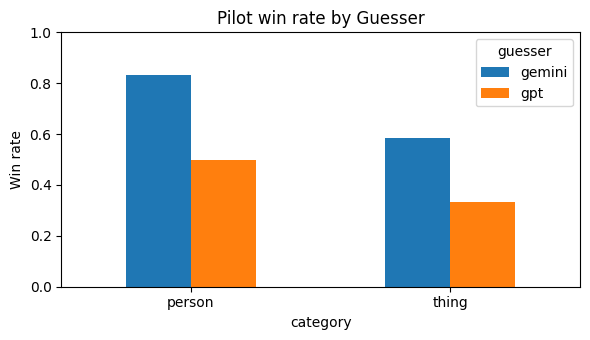

In [ ]:
# ---- Graph: win rate by Guesser and category ----
import matplotlib.pyplot as plt
ax = games.groupby(["category", "guesser"])["won"].mean().unstack().plot.bar(rot=0, figsize=(6, 3.5))
ax.set_ylabel("Win rate"); ax.set_ylim(0, 1); ax.set_title("Pilot win rate by Guesser")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/pilot_winrate.png", dpi=200); plt.show()

In [ ]:
# ---- Print a sample game for the paper ----
def show(game):
    print(f"Secret: {game['word']} | Guesser: {game['guesser']} | Answerer: {game['answerer']}")
    for t in game["turns"]:
        if t["type"] == "question": print(f"Q{t['turn']}: {t['text']}  ->  {t['answer']}")
        else: print(f"G{t['turn']}: {t['text']}  ->  {'CORRECT' if t['correct'] else 'wrong'}")

wins = games[games["won"]].sort_values("turns_used")
show(wins.iloc[len(wins) // 2])   # a median-length winning game

Secret: Katie Ledecky | Guesser: gpt | Answerer: gemini
Q1: Is the person primarily known for being alive in the 21st century?  ->  Yes
Q2: Is the person primarily known for entertainment or sports rather than politics, science, or business?  ->  Yes
Q3: Is the person primarily known as an actor or actress?  ->  No
Q4: Is the person primarily known as a musician or singer?  ->  No
Q5: Is the person primarily known as a professional athlete?  ->  Yes
Q6: Is the person primarily known for playing a team sport?  ->  No
Q7: Is the person primarily known for a combat or individual sport?  ->  Yes
Q8: Is the person primarily known for tennis?  ->  No
Q9: Is the person primarily known for boxing or mixed martial arts?  ->  No
Q10: Is the person primarily known for golf?  ->  No
Q11: Is the person primarily known for motorsports?  ->  No
Q12: Is the person primarily known for gymnastics or figure skating?  ->  No
Q13: Is the person primarily known for track and field or swimming?  ->  Yes
Q14: